In [20]:
import numpy as np
from matplotlib import pyplot as plt
import pickle
import wandb

In [21]:
api = wandb.Api()

username = 'julian-zim-uni-vie'

projects = {
	'll00' : {
		'hgm' : ['hgm_rs-ll00 19.01 16h07 19 ZIM2165_Gcamp7b_worm1-2022_11_28',],
		'bom' : ['bom_rs-ll00 19.01 16h07 19 ZIM2165_Gcamp7b_worm1-2022_11_28',],
	},
	'll67' : {
		'hgm' : [],
		'bom' : [],
	},
}

In [22]:
hyperparams = {
	'll00' : {
		'hgm' : {
			'mpe_loss': {
				'all': np.empty(shape=()),
			},
			'vb_reg_lambda': {
				'all': np.empty(shape=()),
				'mean': {
					'linear': -1.,
					'geometric': -1.,
				},
			},
			'wb_reg_lambda': {
				'all': np.empty(shape=()),
				'mean': {
					'linear': -1.,
					'geometric': -1.,
				},
			},
			'wm_reg_lambda': {
				'all': np.empty(shape=()),
				'mean': {
					'linear': -1.,
					'geometric': -1.,
				},
			},
		},
		'bom' : {
			'mpe_loss': {
				'all': np.empty(shape=()),
			},
			'vb_reg_lambda': {
				'all': np.empty(shape=()),
				'mean': {
					'linear': -1.,
					'geometric': -1.,
				},
			},
			'wb_reg_lambda': {
				'all': np.empty(shape=()),
				'mean': {
					'linear': -1.,
					'geometric': -1.,
				},
			},
		},
	},
	'll67' : {
		'hgm' : {
			'mpe_loss': {
				'all': np.empty(shape=()),
			},
			'vb_reg_lambda': {
				'all': np.empty(shape=()),
				'mean': {
					'linear': -1.,
					'geometric': -1.,
				},
			},
			'wb_reg_lambda': {
				'all': np.empty(shape=()),
				'mean': {
					'linear': -1.,
					'geometric': -1.,
				},
			},
			'wm_reg_lambda': {
				'all': np.empty(shape=()),
				'mean': {
					'linear': -1.,
					'geometric': -1.,
				},
			},
		},
		'bom' : {
			'mpe_loss': {
				'all': np.empty(shape=()),
			},
			'vb_reg_lambda': {
				'all': np.empty(shape=()),
				'mean': {
					'linear': -1.,
					'geometric': -1.,
				},
			},
			'wb_reg_lambda': {
				'all': np.empty(shape=()),
				'mean': {
					'linear': -1.,
					'geometric': -1.,
				},
			},
		},
	},
}

In [23]:
percentile = 5

for ll in ['ll00']:
	for model in ['bom', 'hgm']:
		for project in projects[ll][model]:
			if len(project) == 0:
				continue

			print(f'getting runs for {project}...')
			runs = api.runs(f'{username}/{project}')

			print('sorting them...')
			sorted_runs = sorted(runs, key=lambda run: run.summary.get('mpe_loss', float('inf')))
			best_runs = sorted_runs[:int(percentile / 100 * len(sorted_runs))]

			print(f'{model} averaging mpe loss...')
			hyperparams[ll][model]['mpe_loss']['all'] = np.array([run.summary.get('mpe_loss', float('inf')) for run in sorted_runs])

			print(f'{model} averaging vb...')
			hyperparams[ll][model]['vb_reg_lambda']['all'] = np.array([run.config['vb_reg_lambda'] for run in sorted_runs])

			best_vb_reg_lambdas = np.array([run.config['vb_reg_lambda'] for run in best_runs])
			hyperparams[ll][model]['vb_reg_lambda']['mean']['linear'] = np.mean(best_vb_reg_lambdas)
			hyperparams[ll][model]['vb_reg_lambda']['mean']['geometric'] = np.power(10, np.mean(np.log10(best_vb_reg_lambdas)))

			print(f'{model} averaging wb...')
			hyperparams[ll][model]['wb_reg_lambda']['all'] = np.array([run.config['wb_reg_lambda'] for run in sorted_runs])

			best_wb_reg_lambdas = np.array([run.config['wb_reg_lambda'] for run in best_runs])
			hyperparams[ll][model]['wb_reg_lambda']['mean']['linear'] = np.mean(best_wb_reg_lambdas)
			hyperparams[ll][model]['wb_reg_lambda']['mean']['geometric'] = np.power(10, np.mean(np.log10(best_wb_reg_lambdas)))

			if model == 'hgm':
				print(f'{model} averaging wm...')
				hyperparams[ll][model]['wm_reg_lambda']['all'] = np.array([run.config['wm_reg_lambda'] for run in sorted_runs])

				best_wm_reg_lambdas = np.array([run.config['wm_reg_lambda'] for run in best_runs])
				hyperparams[ll][model]['wm_reg_lambda']['mean']['linear'] = np.mean(best_wm_reg_lambdas)
				hyperparams[ll][model]['wm_reg_lambda']['mean']['geometric'] = np.power(10, np.mean(np.log10(best_wm_reg_lambdas)))

getting runs for bom_rs-ll00 19.01 16h07 19 ZIM2165_Gcamp7b_worm1-2022_11_28...
sorting them...
bom averaging mpe loss...
bom averaging vb...
bom averaging wb...
getting runs for hgm_rs-ll00 19.01 16h07 19 ZIM2165_Gcamp7b_worm1-2022_11_28...
sorting them...
hgm averaging mpe loss...
hgm averaging vb...
hgm averaging wb...
hgm averaging wm...


In [24]:
with open('./hyperparams_rs.pkl', 'wb') as file:
    pickle.dump(hyperparams, file)

In [25]:
with open('./hyperparams_rs.pkl', 'rb') as file:
    hyperparams = pickle.load(file)

In [30]:
for ll in ['ll00']:
	for model in ['bom', 'hgm']:
		for param in ['vb_reg_lambda', 'wb_reg_lambda', 'wm_reg_lambda']:
			if param in hyperparams[ll][model].keys():
				print(f'{ll} {model} {param}:\n\t', f'linear: {hyperparams[ll][model][param]['mean']['linear']:.2E}\tgeometric: {hyperparams[ll][model][param]['mean']['geometric']:.2E}')

ll00 bom vb_reg_lambda:
	 linear: 2.50E-06	geometric: 8.54E-07
ll00 bom wb_reg_lambda:
	 linear: 6.34E-01	geometric: 4.32E-01
ll00 hgm vb_reg_lambda:
	 linear: 7.42E-07	geometric: 3.67E-07
ll00 hgm wb_reg_lambda:
	 linear: 3.80E-02	geometric: 3.28E-02
ll00 hgm wm_reg_lambda:
	 linear: 2.62E-05	geometric: 1.68E-05


In [27]:
hist = False

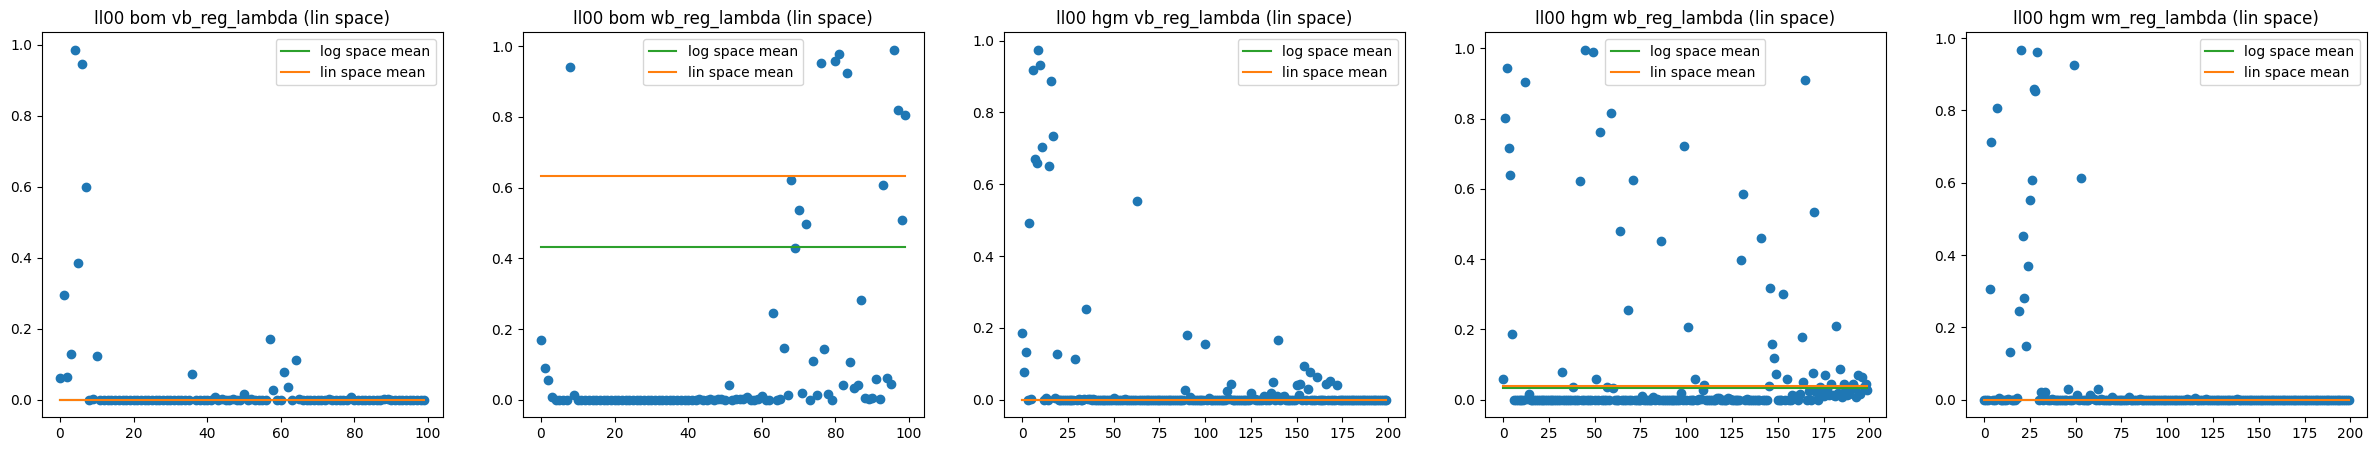

In [28]:
n_params = 5

fig, axes = plt.subplots(1, n_params, figsize=(6 * n_params, n_params), squeeze=False)
idx = 0
for ll in ['ll00']:
	for model in ['bom', 'hgm']:
		for param in ['vb_reg_lambda', 'wb_reg_lambda', 'wm_reg_lambda']:
			if param in hyperparams[ll][model].keys():
				ax = axes[idx // n_params, idx % n_params]
				values = hyperparams[ll][model][param]['all'][::-1]
				means = hyperparams[ll][model][param]['mean']
				ax.set_title(f'{ll} {model} {param} (lin space)')
				if hist:
					ax.hist(values, bins=25)
				else:
					ax.plot(values, marker='o', linestyle='None')
					ax.plot(np.repeat(means['geometric'], values.shape[0]), label='log space mean', color='C2')
					ax.plot(np.repeat(means['linear'], values.shape[0]), label='lin space mean', color='C1')
					ax.legend()
				idx += 1
			else:
				continue

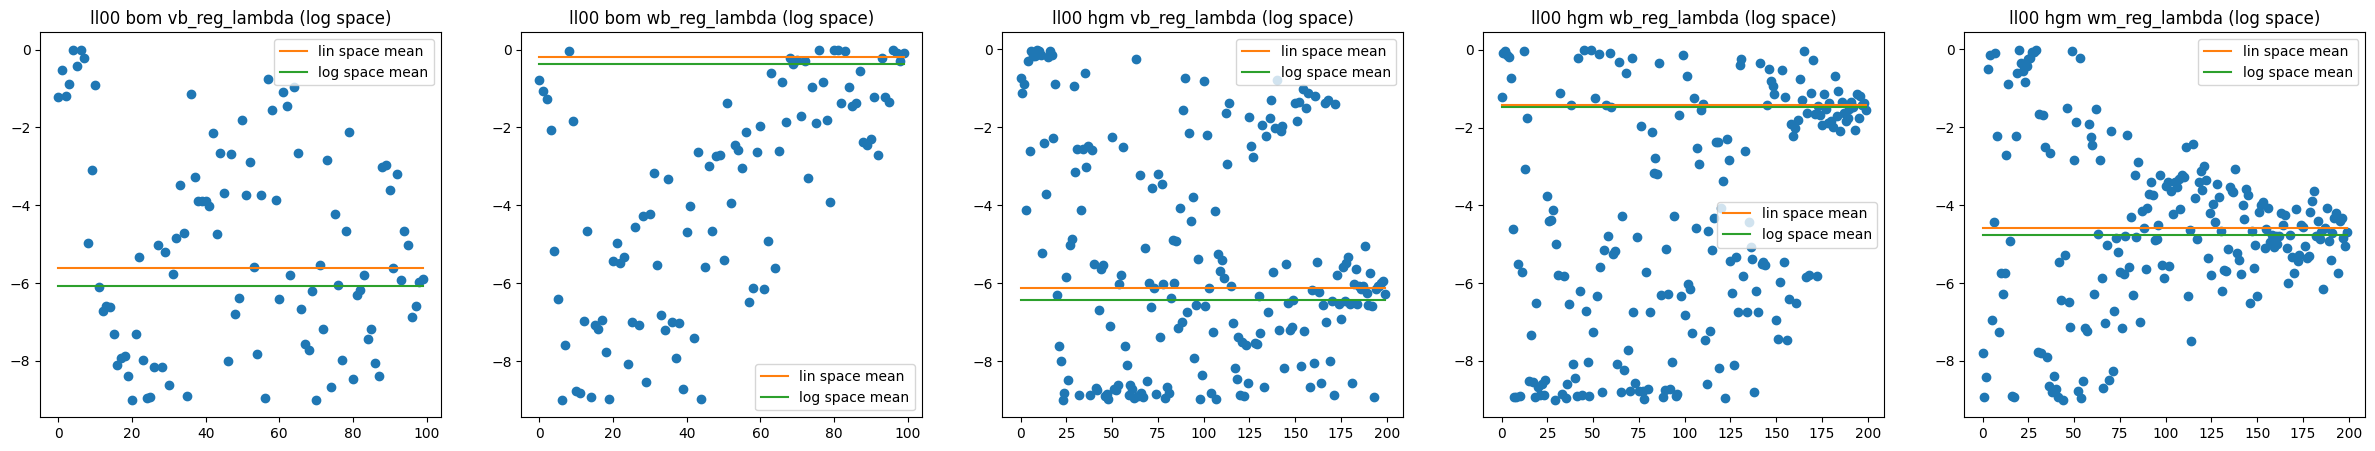

In [29]:
n_params = 5

fig, axes = plt.subplots(1, n_params, figsize=(6 * n_params, n_params), squeeze=False)
idx = 0
for ll in ['ll00']:
	for model in ['bom', 'hgm']:
		for param in ['vb_reg_lambda', 'wb_reg_lambda', 'wm_reg_lambda']:
			if param in hyperparams[ll][model].keys():
				ax = axes[idx // n_params, idx % n_params]
				values = hyperparams[ll][model][param]['all'][::-1]
				means = hyperparams[ll][model][param]['mean']
				ax.set_title(f'{ll} {model} {param} (log space)')
				if hist:
					ax.hist(np.log10(values), bins=25)
				else:
					ax.plot(np.log10(values), marker='o', linestyle='None')
					ax.plot(np.repeat(np.log10(means['linear']), values.shape[0]), label='lin space mean', color='C1')
					ax.plot(np.repeat(np.log10(means['geometric']), values.shape[0]), label='log space mean', color='C2')

					ax.legend()
				idx += 1
			else:
				continue